In [130]:
import scipy.io, scipy.stats
import matplotlib.pyplot as plt
import numpy as np
import tqdm
import pickle

In [83]:
# Load Nguyen's data
data_path = '/home/niklasz/Desktop/ucla/research_work/nguyen_data_analysis/set1'
train_iters = list(range(100,2100, 100))
test_iters = list(range(1,51))
file_name = f'behavior_output_{train_iters[0]}iters_test_{test_iters[0]}.mat'
example_mat_file = scipy.io.loadmat(f'{data_path}/{file_name}')

# Tensors of following dimensions: training iteration (Tr) x episode (E) x timestep (Ti) x activations (A)
episode_length, activation_size = example_mat_file['R1'].shape
agent_1_activations = np.zeros((len(train_iters),len(test_iters),episode_length,activation_size))
agent_2_activations = np.zeros((len(train_iters),len(test_iters),episode_length,activation_size))

mat_files = {}
for i, tr in enumerate(train_iters):
    mat_files[tr] = {}
    for j,te in enumerate(test_iters):
        file_name = f'behavior_output_{tr}iters_test_{te}.mat'
        mat_file = scipy.io.loadmat(f'{data_path}/{file_name}')
        agent_1_activations[i,j] = mat_file['R1']
        agent_2_activations[i,j] = mat_file['R2']

In [84]:
# Calculate mean activity
correlatedActivity = np.zeros((len(train_iters), len(test_iters)))
temporalControl = np.zeros(correlatedActivity.shape)
crosspairControl = np.zeros(correlatedActivity.shape)

a1_z_scored = scipy.stats.zscore(agent_1_activations, ddof=1, axis=2) # z-score across the timestep dimension dimension
a2_z_scored = scipy.stats.zscore(agent_2_activations, ddof=1, axis=2) # z-score across the timestep dimension dimension

# TODO undo this for my activation logic
# It seems there is some dirty data in the activations (0 activations for a column). When z-scoring on this column
# The 0-division makes it NaN. We will replace NaN with 0
a1_z_scored = np.nan_to_num(a1_z_scored)
a2_z_scored = np.nan_to_num(a2_z_scored)

# Mean Activations
a1_mean = np.mean(a1_z_scored, axis=3) # Mean along the activation axis
a2_mean = np.mean(a2_z_scored, axis=3) # The resulting tensor has dim: Tr x E x Ti

In [85]:
# Correlation in means over time
for i in range(0,a1_mean.shape[0]):
    for j in range(0,a1_mean.shape[1]):
        correlatedActivity[i,j] = scipy.stats.pearsonr(a1_mean[i,j], a2_mean[i,j])[0]

In [86]:
# Correlation - Cross-pair control
shifted_indices = np.roll(np.arange(0,len(test_iters)),10)
for i in range(0,a1_mean.shape[0]):
    for j in range(0,a1_mean.shape[1]):
        crosspairControl[i,j] = scipy.stats.pearsonr(a1_mean[i,j], a2_mean[i,shifted_indices[j]])[0]

In [87]:
# Correlation - Temporal control
shuffles = 1000
for i in tqdm.tqdm(range(0,a1_mean.shape[0])):
    for j in range(0,a1_mean.shape[1]):
        # Shuffle the data 1000 times and get the correlation each time
        shuffle_distances = np.random.randint(10,episode_length - 10,(shuffles,2))
        shuffled_correlations = np.zeros(shuffles)
        for idx,(s1,s2) in enumerate(shuffle_distances):
            shuffled_correlations[idx] = scipy.stats.pearsonr(np.roll(a1_mean[i,j],s1), np.roll(a2_mean[i,j],s2))[0]
        temporalControl[i,j] = np.median(shuffled_correlations)

100%|██████████| 20/20 [01:18<00:00,  3.92s/it]


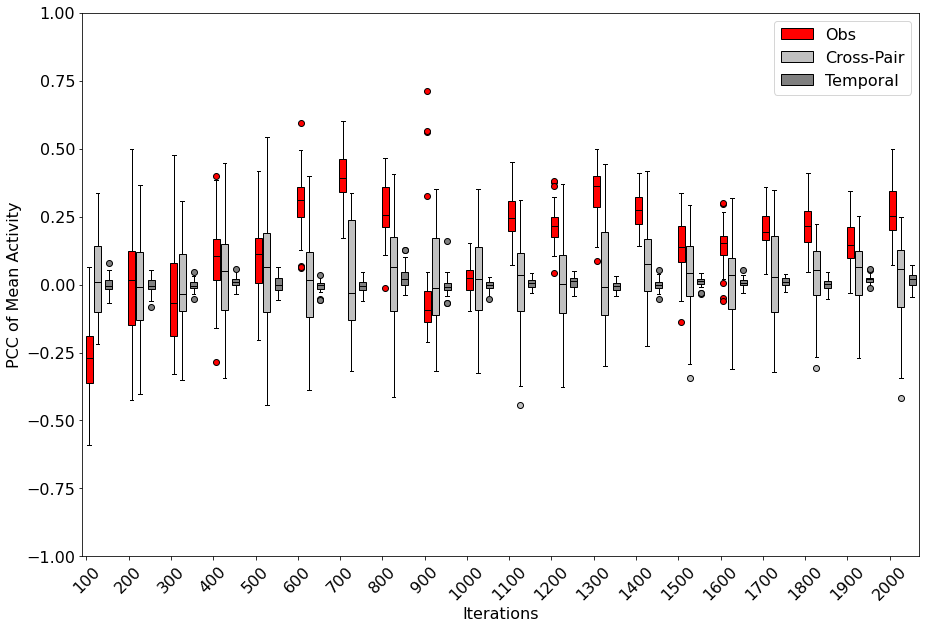

In [125]:
fig = plt.figure(figsize =(15, 10))
plt.rcParams.update({'font.size': 16})

# Creating plot
box_count = crosspairControl.shape[0]
box_width = 0.5
box_spacing = 3
bplot3 = plt.boxplot(temporalControl.T, patch_artist=True, flierprops={'markerfacecolor':'grey'}, boxprops=dict(facecolor="grey"),
                     positions=np.arange(box_count)*box_spacing+1.6,widths=box_width)
bplot2 = plt.boxplot(crosspairControl.T, patch_artist=True, flierprops={'markerfacecolor':'silver'}, boxprops=dict(facecolor="silver"),
                     positions=np.arange(box_count)*box_spacing+0.8,widths=box_width)
bplot1 = plt.boxplot(correlatedActivity.T, patch_artist=True, flierprops={'markerfacecolor':'red'}, boxprops=dict(facecolor="red"),
                     positions=np.arange(box_count)*box_spacing+0.2,widths=box_width)
plt.ylim([-1,1])
plt.ylabel('PCC of Mean Activity')
plt.xlabel('Iterations')
ticks = np.arange(0, len(train_iters) * box_spacing, box_spacing)
plt.xticks(ticks, train_iters)
plt.xticks(rotation=45)

plt.legend([bplot1["boxes"][0], bplot2["boxes"][0], bplot3["boxes"][0]], ['Obs', 'Cross-Pair', 'Temporal'], loc='upper right')

# Colour medians
for plot in [bplot1, bplot2, bplot3]:
    for median in plot['medians']:
        median.set_color('black')


# show plot
plt.savefig('/home/niklasz/Desktop/ucla/research_work/nguyen_data_analysis/charts/pcc_python.png')
plt.show()